# South Korea Demographic Data Analysis (2000–2022)

## 1. Project Introduction

### Overview

This project performs Exploratory Data Analysis (EDA) on South Korea's demographic dataset covering January 2000 to June 2022.

The dataset contains monthly demographic information across different regions of South Korea, including births, deaths, marriages, divorces, and natural population growth.

The analysis aims to understand demographic patterns, identify population trends, examine regional differences, and discover meaningful relationships between demographic indicators using statistical methods and data visualisation.

### Objectives

- Understand the structure and characteristics of the dataset.
- Examine data types, memory usage, and data quality.
- Identify and analyse missing values and duplicate records.
- Calculate descriptive statistics for numerical variables.
- Explore distributions of demographic indicators.
- Analyse birth, death, and natural population growth trends over time.
- Compare demographic patterns across different regions.
- Investigate correlations between demographic variables.
- Derive meaningful insights through exploratory analysis and visualisation.

### Tools and Technologies

- Python
- Pandas – Data manipulation and analysis
- NumPy – Numerical operations
- Matplotlib – Data visualisation
- Seaborn – Statistical visualisation
- Jupyter Notebook – Interactive analysis

### Dataset Overview

- **Country:** South Korea
- **Time Period:** January 2000 – June 2022
- **Total Records:** 4,860
- **Total Columns:** 12
- **Geographical Coverage:** 17 regions and the national aggregate (Whole country)
- **Data Frequency:** Monthly

### Dataset Details

- **Platform:** Kaggle
- **Dataset Name:** Korean Demographics (2000–2022)
- **Dataset URL:** https://www.kaggle.com/datasets/alexandrepetit881234/korean-demographics-20002022
- **File Name:** Korean_demographics_2000-2022.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Korean_demographics_2000-2022.csv')

In [3]:
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%m/%d/%Y',
    errors='coerce'
)

## 2. Structural Overview

This section examines the basic structure of the dataset, including its dimensions, column names, data types, memory usage, date range, and sample records.

The purpose is to understand the dataset before performing further exploratory analysis.

In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (4860, 12)


In [5]:
print("\nDate Range:")
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())


Date Range:
Start Date: 2000-01-01 00:00:00
End Date: 2022-06-01 00:00:00


In [6]:
print(df['Date'].dtype)

datetime64[ns]


In [7]:
print(df['Date'].isnull().sum())

0


In [8]:
print("========== DATASET STRUCTURE ==========")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


========== DATASET STRUCTURE ==========
Rows: 4860
Columns: 12


In [9]:
print(df.columns.tolist())

['Date', 'Region', 'Birth', 'Birth_rate', 'Death', 'Death_rate', 'Divorce', 'Divorce_rate', 'Marriage', 'Marriage_rate', 'Natural_growth', 'Natural_growth_rate']


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4860 entries, 0 to 4859
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 4860 non-null   datetime64[ns]
 1   Region               4860 non-null   object        
 2   Birth                4716 non-null   float64       
 3   Birth_rate           4709 non-null   float64       
 4   Death                4716 non-null   float64       
 5   Death_rate           4709 non-null   float64       
 6   Divorce              4716 non-null   float64       
 7   Divorce_rate         4709 non-null   float64       
 8   Marriage             4716 non-null   float64       
 9   Marriage_rate        4709 non-null   float64       
 10  Natural_growth       4716 non-null   float64       
 11  Natural_growth_rate  4709 non-null   float64       
dtypes: datetime64[ns](1), float64(10), object(1)
memory usage: 455.8+ KB


In [11]:
df.info(memory_usage='deep')
print(
    f"\nTotal Memory: "
    f"{df.memory_usage(deep=True).sum() / 1024:.2f} KB"
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4860 entries, 0 to 4859
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 4860 non-null   datetime64[ns]
 1   Region               4860 non-null   object        
 2   Birth                4716 non-null   float64       
 3   Birth_rate           4709 non-null   float64       
 4   Death                4716 non-null   float64       
 5   Death_rate           4709 non-null   float64       
 6   Divorce              4716 non-null   float64       
 7   Divorce_rate         4709 non-null   float64       
 8   Marriage             4716 non-null   float64       
 9   Marriage_rate        4709 non-null   float64       
 10  Natural_growth       4716 non-null   float64       
 11  Natural_growth_rate  4709 non-null   float64       
dtypes: datetime64[ns](1), float64(10), object(1)
memory usage: 696.5 KB

Total Memory: 696.49 

In [12]:
display(df.head())


,Date,Region,Birth,Birth_rate,Death,Death_rate,Divorce,Divorce_rate,Marriage,Marriage_rate,Natural_growth,Natural_growth_rate
0,2000-01-01,Busan,3752.0,11.61,1875.0,5.8,814.0,2.5,2435.0,7.5,1877.0,5.8
1,2000-01-01,Chungcheongbuk-do,1903.0,15.06,924.0,7.3,220.0,1.7,828.0,6.6,979.0,7.7
2,2000-01-01,Chungcheongnam-do,2398.0,14.75,1466.0,9.0,321.0,2.0,1055.0,6.5,932.0,5.7
3,2000-01-01,Daegu,3057.0,14.39,1117.0,5.3,422.0,2.0,1577.0,7.4,1940.0,9.1
4,2000-01-01,Daejeon,1859.0,16.08,565.0,4.9,280.0,2.4,868.0,7.5,1294.0,11.2


In [13]:
display(df.tail())

,Date,Region,Birth,Birth_rate,Death,Death_rate,Divorce,Divorce_rate,Marriage,Marriage_rate,Natural_growth,Natural_growth_rate
4855,2022-06-01,Jeollanam-do,565.0,3.8,1369.0,9.1,299.0,2.0,479.0,3.2,-805.0,-5.4
4856,2022-06-01,Sejong,248.0,7.9,106.0,3.4,43.0,1.4,123.0,3.9,141.0,4.5
4857,2022-06-01,Seoul,3137.0,4.1,3631.0,4.7,1088.0,1.4,2630.0,3.4,-494.0,-0.6
4858,2022-06-01,Ulsan,443.0,4.8,434.0,4.7,154.0,1.7,316.0,3.5,9.0,0.1
4859,2022-06-01,Whole country,18830.0,4.5,24850.0,5.9,7586.0,1.8,14898.0,3.5,-6019.0,-1.4


## 3. Duplicate Data Analysis

Duplicate records can affect the accuracy of statistical analysis.
This section identifies duplicate rows and duplicate Date-Region combinations
to ensure data consistency.

In [14]:
total_duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", total_duplicates)

duplicate_keys = df.duplicated(
    subset=['Date', 'Region']
).sum()

print("Duplicate Date-Region Combinations:", duplicate_keys)

if total_duplicates > 0:
    display(df[df.duplicated(keep=False)])
else:
    print("No complete duplicate records found.")

if duplicate_keys > 0:
    display(
        df[df.duplicated(
            subset=['Date', 'Region'],
            keep=False
        )].sort_values(['Date', 'Region'])
    )
else:
    print("No duplicate Date-Region combinations found.")

Total Duplicate Rows: 0
Duplicate Date-Region Combinations: 0
No complete duplicate records found.
No duplicate Date-Region combinations found.


## 4. Missing Value Analysis

Missing value analysis helps identify incomplete records
and data quality issues in the dataset.

This section examines missing values by column, percentage,
and geographical region using statistical summaries and visualisations.

In [15]:
missing_count = df.isnull().sum()

In [16]:
missing_percentage = (df.isnull().mean() * 100).round(2)

In [17]:
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage (%)': missing_percentage
})

In [18]:
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Values', ascending=False)

display(missing_summary)

,Missing Values,Missing Percentage (%)
Birth_rate,151,3.11
Death_rate,151,3.11
Natural_growth_rate,151,3.11
Divorce_rate,151,3.11
Marriage_rate,151,3.11
Birth,144,2.96
Divorce,144,2.96
Death,144,2.96
Marriage,144,2.96
Natural_growth,144,2.96


In [19]:
print("\nTotal Missing Cells:", df.isnull().sum().sum())

print(
    "Total Rows with Missing Values:",
    df.isnull().any(axis=1).sum()
)


Total Missing Cells: 1475
Total Rows with Missing Values: 151


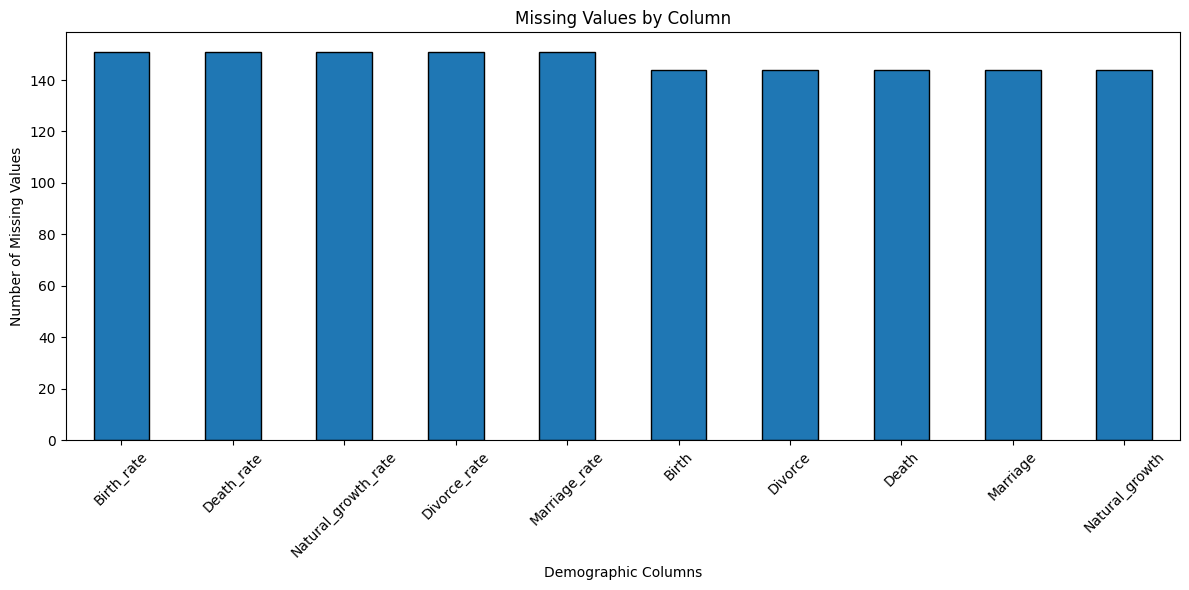

In [20]:
plt.figure(figsize=(12, 6))

missing_summary['Missing Values'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Missing Values by Column')
plt.xlabel('Demographic Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

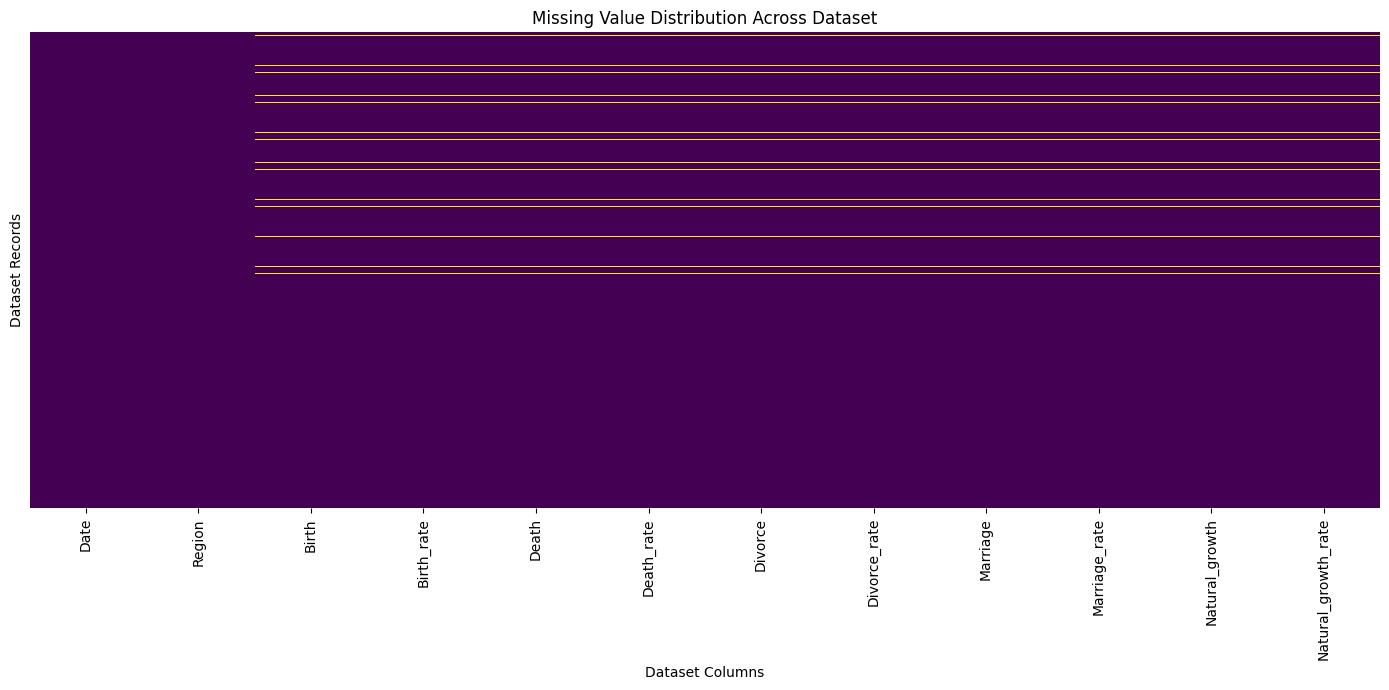

In [21]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Value Distribution Across Dataset')
plt.xlabel('Dataset Columns')
plt.ylabel('Dataset Records')

plt.tight_layout()
plt.show()


Missing Values by Region:


,missing_count
Region,
Sejong,1475
Busan,0
Chungcheongbuk-do,0
Chungcheongnam-do,0
Daejeon,0
Daegu,0
Gwangju,0
Gyeonggi-do,0
Gyeongsangbuk-do,0


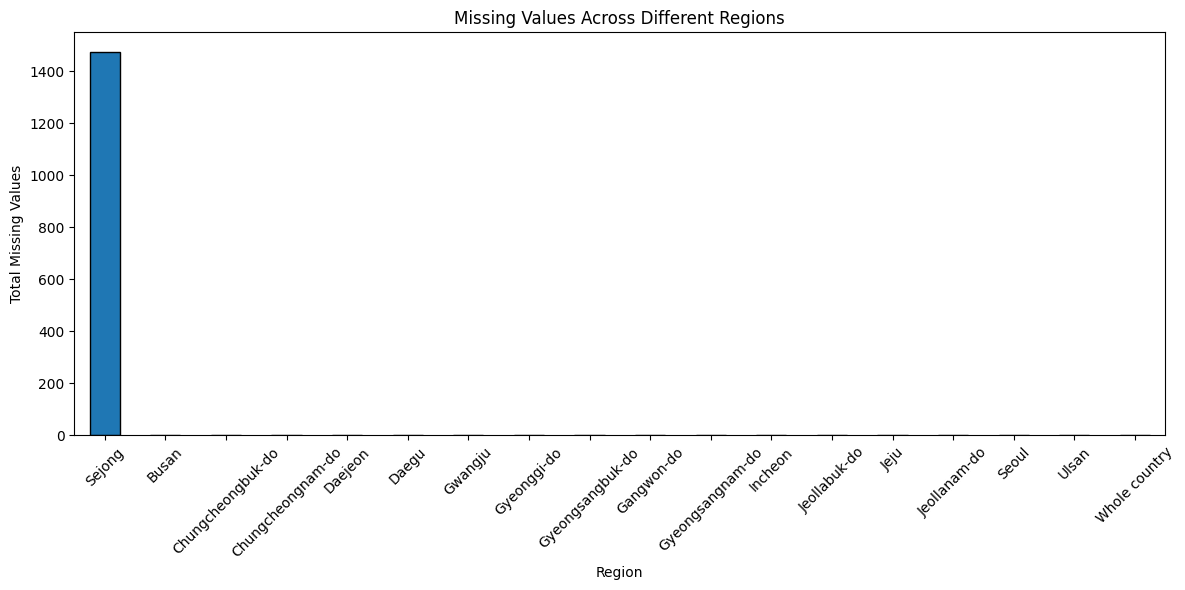

In [22]:
region_missing = (
    df.assign(missing_count=df.isnull().sum(axis=1))
      .groupby('Region')['missing_count']
      .sum()
      .sort_values(ascending=False)
)

print("Missing Values by Region:")
display(region_missing)

plt.figure(figsize=(12, 6))

region_missing.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Missing Values Across Different Regions')
plt.xlabel('Region')
plt.ylabel('Total Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Interpretation of Missing Value Analysis

The missing value analysis reveals that 1,475 cells are missing across 151 records in the dataset.

- The five demographic count columns contain 144 missing values each.
- The five demographic rate columns contain 151 missing values each.
- All missing values are concentrated in the Sejong region, while the other 17 regions have complete records.
- A total of 144 Sejong records have all ten demographic measurements missing. An additional seven records have only the five rate-based measurements missing.

This indicates that the missing data is concentrated in one geographical region rather than being randomly distributed across the dataset.

**Data Handling Decision:** Missing values are retained without imputation to avoid introducing artificial demographic measurements into the exploratory analysis.

## 5. Descriptive Statistical Analysis

Descriptive statistical analysis helps understand the distribution
and characteristics of numerical demographic variables.

This section examines mean, median, standard deviation,
minimum, maximum, and quartiles to identify patterns
and variations in the dataset.

In [23]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

In [24]:
statistics = df[numeric_columns].describe().T

In [25]:
statistics['median'] = df[numeric_columns].median()

In [26]:
statistics = statistics[
    ['count', 'mean', 'median', 'std',
     'min', '25%', '50%', '75%', 'max']
]

display(statistics.round(2))


,count,mean,median,std,min,25%,50%,75%,max
Birth,4716.0,4138.17,1431.50,8450.11,67.0,1004.75,1431.50,2327.00,61644.00
Birth_rate,4709.0,8.74,8.83,2.36,3.1,7.21,8.83,10.07,18.77
Death,4716.0,2556.82,1149.00,5029.23,52.0,692.50,1149.00,1721.00,44487.00
Death_rate,4709.0,5.86,5.60,1.59,3.1,4.50,5.60,7.00,15.70
Divorce,4716.0,1130.37,392.00,2287.59,10.0,278.00,392.00,651.25,15517.00
Divorce_rate,4709.0,2.35,2.30,0.49,0.8,2.00,2.30,2.60,5.00
Marriage,4716.0,2786.63,908.50,5784.57,37.0,630.00,908.50,1535.25,46099.00
Marriage_rate,4709.0,5.61,5.50,1.46,2.4,4.60,5.50,6.50,12.40
Natural_growth,4716.0,1581.35,444.50,4157.93,-21562.0,105.75,444.50,941.00,38286.00
Natural_growth_rate,4709.0,2.88,2.90,3.26,-11.2,0.70,2.90,5.20,13.70


### Interpretation of Descriptive Statistics

- Birth and marriage counts show considerable variation across different regions and time periods.
- The mean values are higher than the median for most count-based variables, indicating right-skewed distributions.
- Natural Growth has a minimum value of -21,562, indicating periods where deaths exceeded births.
- Natural Growth Rate ranges from -11.2 to 13.7, showing both population decline and growth.
- The rate-based variables contain 4,709 valid observations, while count-based variables contain 4,716 valid observations.

These statistics highlight variations in demographic patterns across South Korea between 2000 and 2022.

## 6. Categorical Data Analysis

Categorical data analysis helps understand the distribution
of non-numerical variables in the dataset.

This section examines the frequency of each region
and identifies the number of records available for each region.

In [27]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

for column in categorical_columns:
    print(f"\nValue Counts for {column}:")
    display(df[column].value_counts())


Value Counts for Region:


,count
Region,
Busan,270
Chungcheongbuk-do,270
Chungcheongnam-do,270
Daegu,270
Daejeon,270
Gangwon-do,270
Gwangju,270
Gyeonggi-do,270
Gyeongsangbuk-do,270


In [28]:
print(df['Region'].nunique())

18


In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

national_df = df[df['Region'] == 'Whole country'].copy()

regional_df = df[df['Region'] != 'Whole country'].copy()

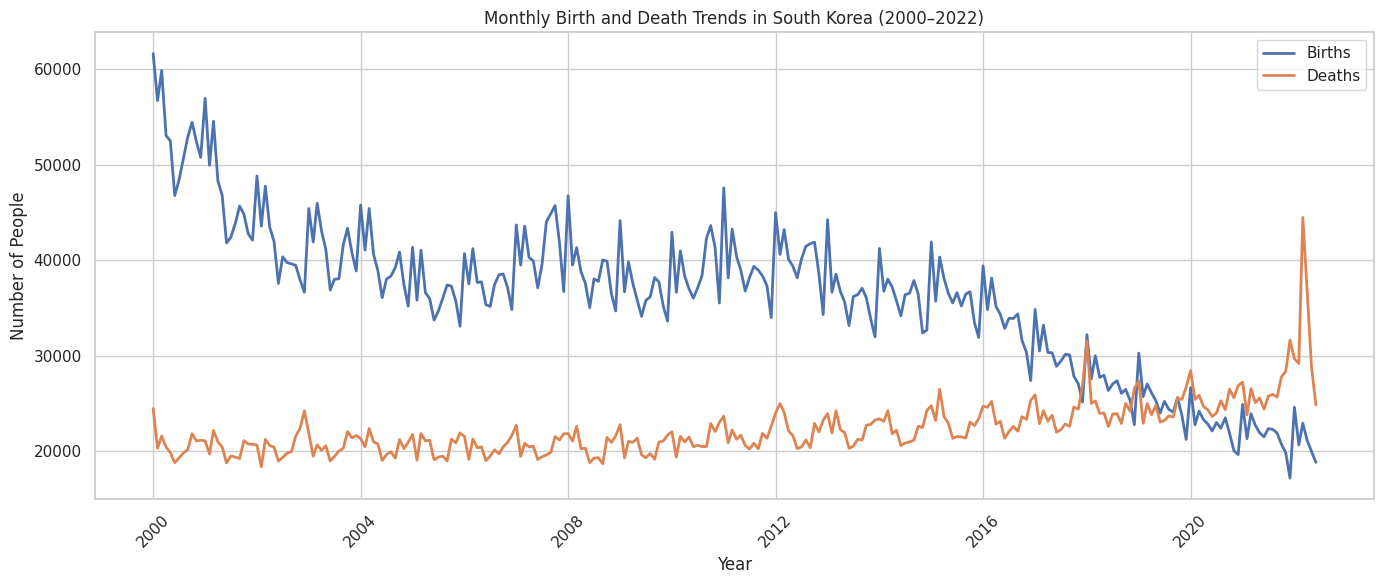

In [30]:
plt.figure(figsize=(14, 6))

plt.plot(
    national_df['Date'],
    national_df['Birth'],
    label='Births',
    linewidth=2
)

plt.plot(
    national_df['Date'],
    national_df['Death'],
    label='Deaths',
    linewidth=2
)

plt.title('Monthly Birth and Death Trends in South Korea (2000–2022)')
plt.xlabel('Year')
plt.ylabel('Number of People')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The analysis shows a continuous decline in births and an increase
in deaths over the study period. This indicates a significant
change in South Korea's demographic pattern.

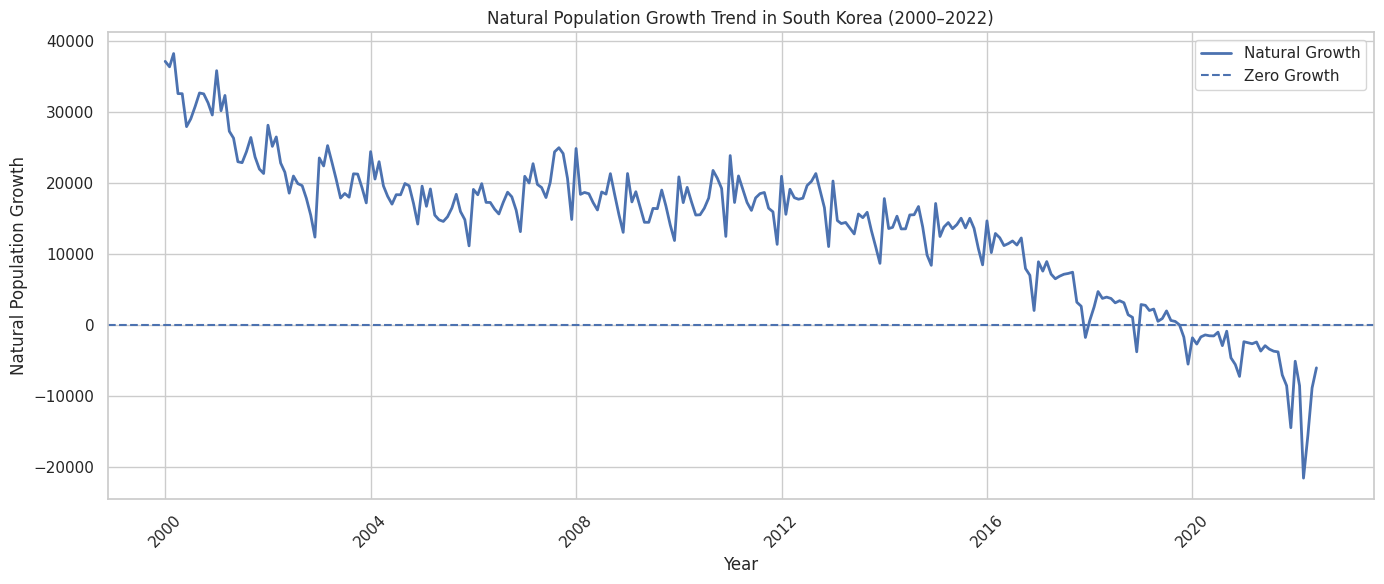

In [31]:
plt.figure(figsize=(14, 6))

plt.plot(
    national_df['Date'],
    national_df['Natural_growth'],
    linewidth=2,
    label='Natural Growth'
)

plt.axhline(
    y=0,
    linestyle='--',
    label='Zero Growth'
)

plt.title('Natural Population Growth Trend in South Korea (2000–2022)')
plt.xlabel('Year')
plt.ylabel('Natural Population Growth')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The natural population growth trend shows a significant decline.
South Korea recorded negative average natural growth from 2020,
indicating that deaths exceeded births.

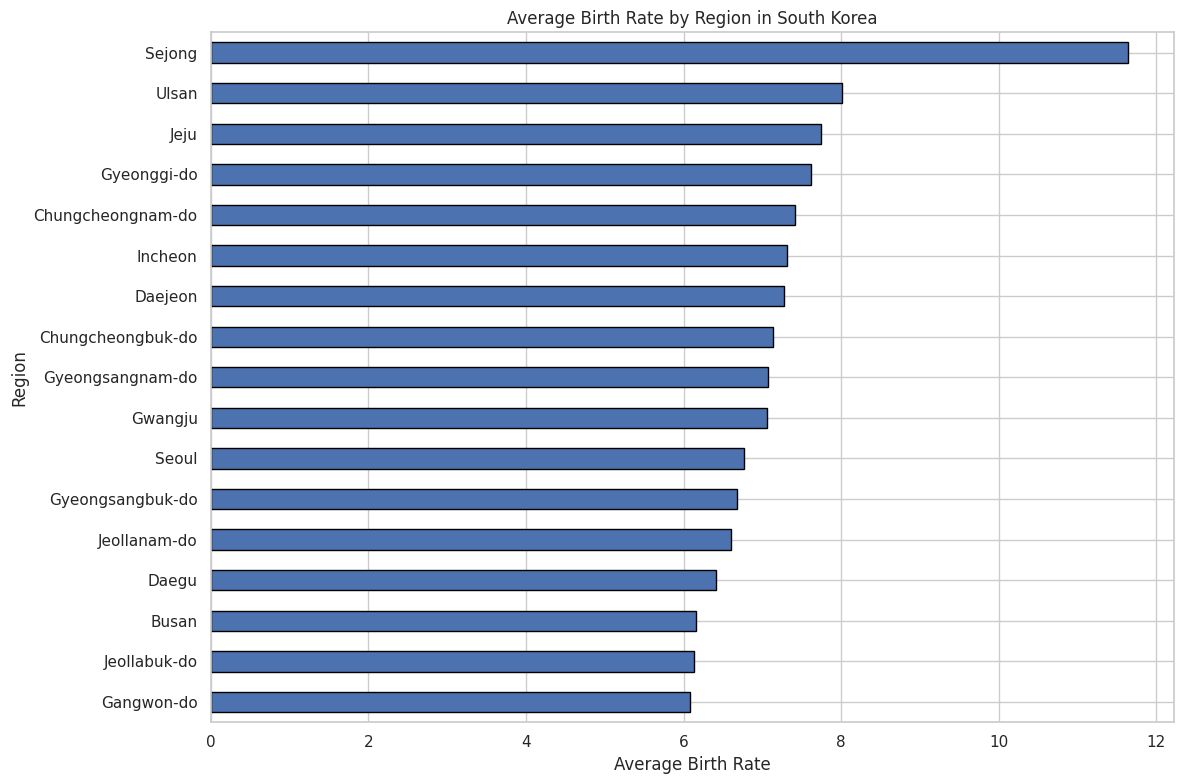

In [32]:
regional_birth = regional_df[
    (regional_df['Date'] >= '2012-08-01') &
    (regional_df['Date'] <= '2022-06-30')
]

birth_rate_region = (
    regional_birth.groupby('Region')['Birth_rate']
    .mean()
    .sort_values()
)

plt.figure(figsize=(12, 8))

birth_rate_region.plot(
    kind='barh',
    edgecolor='black'
)

plt.title('Average Birth Rate by Region in South Korea')
plt.xlabel('Average Birth Rate')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

The regional comparison reveals considerable differences
in average birth rates. Sejong recorded the highest average
birth rate of 11.64, while Gangwon-do recorded the lowest
average of 6.08 during the selected period.

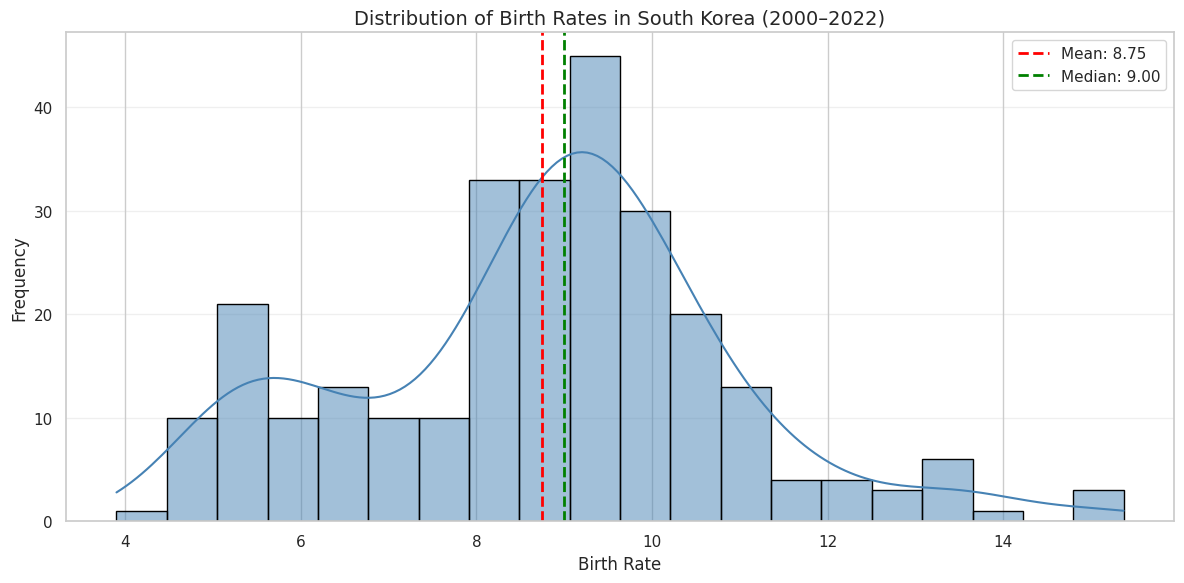

In [33]:
plt.figure(figsize=(12, 6))

birth_rate_data = national_df['Birth_rate'].dropna()

sns.histplot(
    birth_rate_data,
    bins=20,
    kde=True,
    color='steelblue',
    edgecolor='black'
)

plt.axvline(
    birth_rate_data.mean(),
    color='red',
    linestyle='--',
    linewidth=2,
    label=f"Mean: {birth_rate_data.mean():.2f}"
)

plt.axvline(
    birth_rate_data.median(),
    color='green',
    linestyle='--',
    linewidth=2,
    label=f"Median: {birth_rate_data.median():.2f}"
)

plt.title(
    'Distribution of Birth Rates in South Korea (2000–2022)',
    fontsize=14
)

plt.xlabel('Birth Rate', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [34]:
print("Birth Rate Distribution Summary")
print("Mean:", round(birth_rate_data.mean(), 2))
print("Median:", round(birth_rate_data.median(), 2))
print("Standard Deviation:", round(birth_rate_data.std(), 2))
print("Skewness:", round(birth_rate_data.skew(), 3))
print("Minimum:", birth_rate_data.min())
print("Maximum:", birth_rate_data.max())

Birth Rate Distribution Summary
Mean: 8.75
Median: 9.0
Standard Deviation: 2.14
Skewness: 0.113
Minimum: 3.9
Maximum: 15.37


### Interpretation of Birth Rate Distribution

The histogram illustrates the distribution of monthly birth rates
in South Korea between 2000 and 2022.

- Most birth rate observations are concentrated around the range
  of approximately 7 to 10.
- The average birth rate is 8.75, while the median is 9.00.
- The standard deviation is 2.14, indicating variation in birth
  rates throughout the observation period.
- The skewness value of approximately 0.11 indicates a nearly
  symmetrical distribution with a very slight positive skew.
- The birth rate ranges from 3.90 to 15.37.

Overall, the distribution shows that birth rates are concentrated
around the central range, with relatively few observations at
the extreme values.

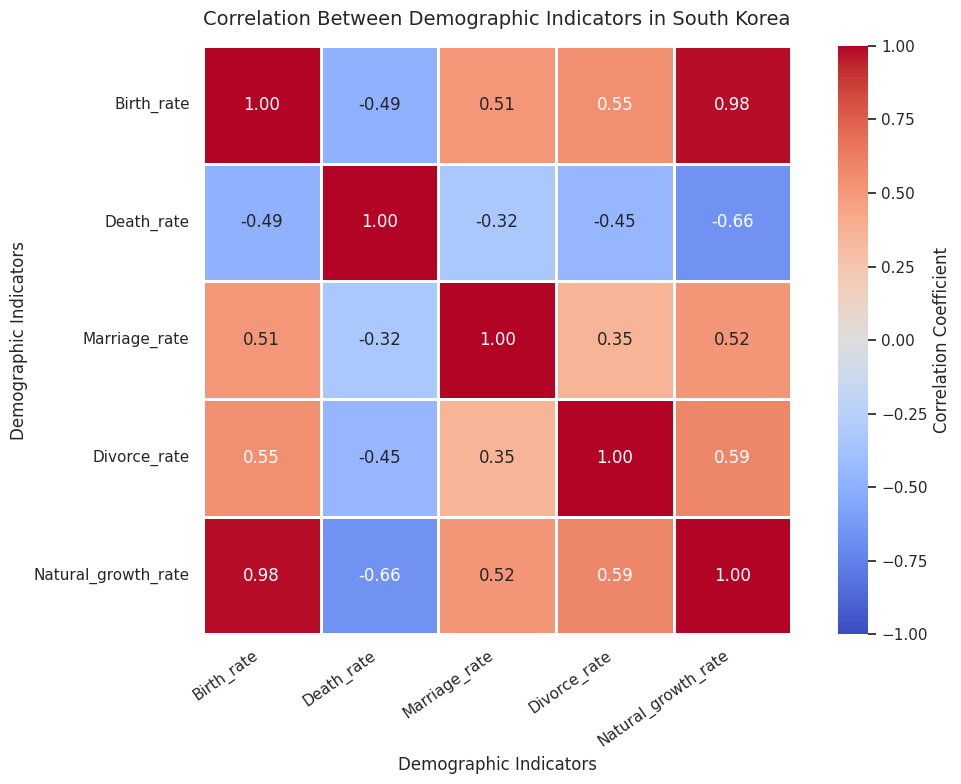

In [35]:
rate_columns = [
    'Birth_rate',
    'Death_rate',
    'Marriage_rate',
    'Divorce_rate',
    'Natural_growth_rate'
]

correlation = national_df[rate_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.8,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.title(
    'Correlation Between Demographic Indicators in South Korea',
    fontsize=14,
    pad=15
)

plt.xlabel('Demographic Indicators', fontsize=12)
plt.ylabel('Demographic Indicators', fontsize=12)

plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [36]:
print("Correlation Matrix:")
display(correlation.round(3))

Correlation Matrix:


,Birth_rate,Death_rate,Marriage_rate,Divorce_rate,Natural_growth_rate
Birth_rate,1.000,-0.490,0.510,0.553,0.978
Death_rate,-0.490,1.000,-0.322,-0.452,-0.662
Marriage_rate,0.510,-0.322,1.000,0.352,0.516
Divorce_rate,0.553,-0.452,0.352,1.000,0.586
Natural_growth_rate,0.978,-0.662,0.516,0.586,1.000


### Interpretation of Correlation Heatmap

The correlation heatmap highlights the relationships between
different demographic indicators in South Korea.

Key observations:

- Birth Rate and Natural Growth Rate show a very strong
  positive correlation of approximately 0.98.
- Death Rate and Natural Growth Rate show a negative
  correlation of approximately -0.66.
- Birth Rate and Death Rate have a moderate negative
  correlation of approximately -0.49.
- Birth Rate and Marriage Rate show a positive
  correlation of approximately 0.51.
- Divorce Rate and Natural Growth Rate show a positive
  correlation of approximately 0.59.

The strong positive relationship between Birth Rate and
Natural Growth Rate indicates that these variables tend
to move in the same direction.

Overall, the heatmap helps identify positive and negative
relationships between demographic indicators.

Note: Correlation indicates statistical association and
does not necessarily imply causation.

/tmp/ipykernel_29176/134015389.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


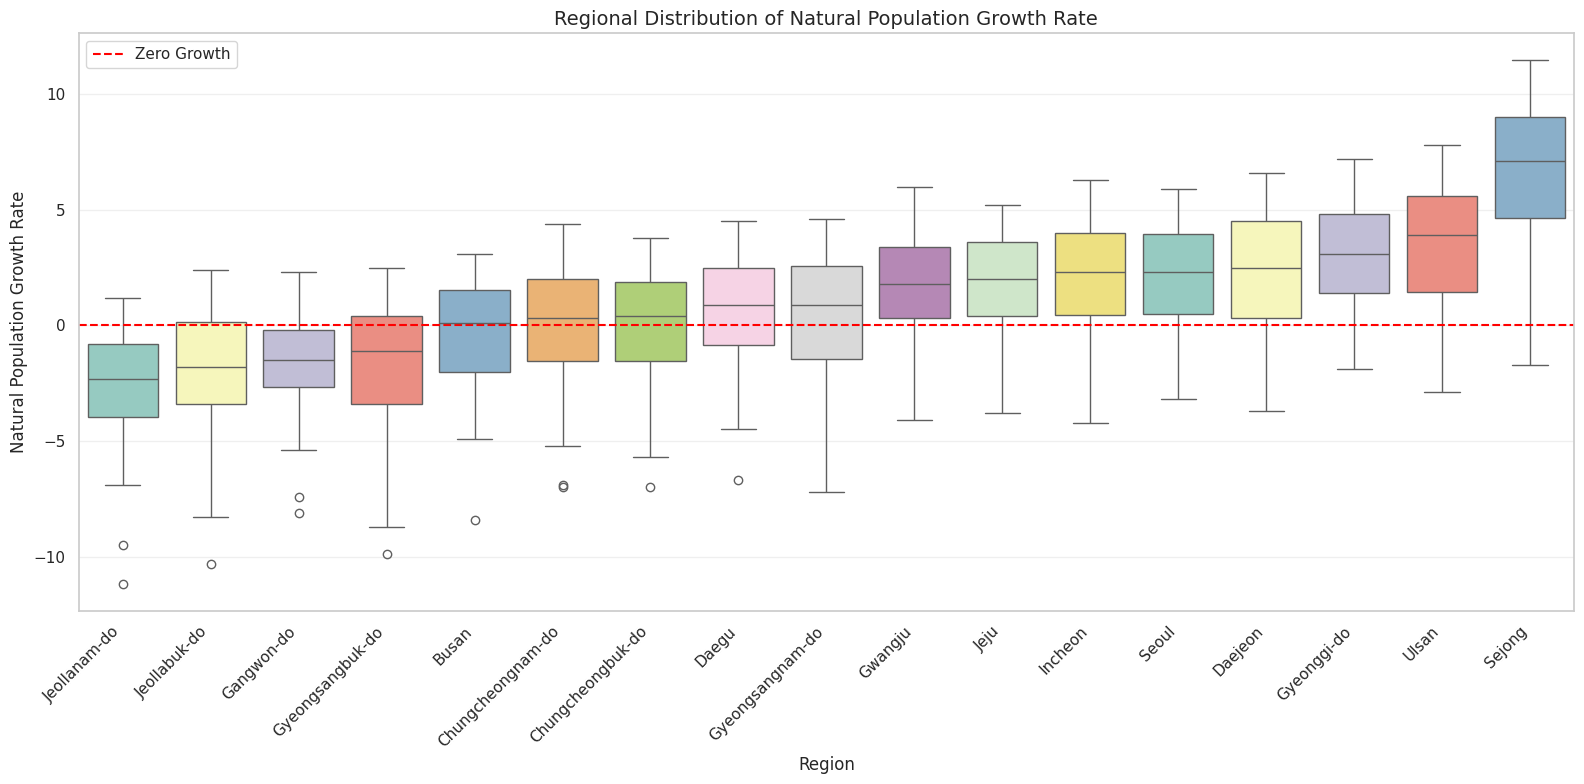

In [37]:
regional_common = regional_df[
    (regional_df['Date'] >= '2012-08-01') &
    (regional_df['Date'] <= '2022-06-30')
].copy()

boxplot_data = regional_common.dropna(
    subset=['Region', 'Natural_growth_rate']
)

region_order = (
    boxplot_data.groupby('Region')['Natural_growth_rate']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=boxplot_data,
    x='Region',
    y='Natural_growth_rate',
    order=region_order,
    palette='Set3',
    showfliers=True
)

plt.title(
    'Regional Distribution of Natural Population Growth Rate',
    fontsize=14
)

plt.xlabel('Region', fontsize=12)
plt.ylabel('Natural Population Growth Rate', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Zero Growth'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
regional_summary = (
    boxplot_data.groupby('Region')['Natural_growth_rate']
    .agg(
        Median='median',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Minimum='min',
        Maximum='max'
    )
)

regional_summary['IQR'] = (
    regional_summary['Q3'] - regional_summary['Q1']
)

display(regional_summary.round(2))

,Median,Q1,Q3,Minimum,Maximum,IQR
Region,,,,,,
Busan,0.1,-2.00,1.55,-8.4,3.1,3.55
Chungcheongbuk-do,0.4,-1.55,1.90,-7.0,3.8,3.45
Chungcheongnam-do,0.3,-1.55,2.00,-7.0,4.4,3.55
Daegu,0.9,-0.85,2.50,-6.7,4.5,3.35
Daejeon,2.5,0.30,4.50,-3.7,6.6,4.20
Gangwon-do,-1.5,-2.65,-0.20,-8.1,2.3,2.45
Gwangju,1.8,0.30,3.40,-4.1,6.0,3.10
Gyeonggi-do,3.1,1.40,4.80,-1.9,7.2,3.40
Gyeongsangbuk-do,-1.1,-3.40,0.40,-9.9,2.5,3.80


### Interpretation of Regional Box Plot

The box plot compares the distribution of natural population
growth rates across different regions of South Korea from
August 2012 to June 2022.

Key observations:

- Sejong has the highest median natural growth rate of
  approximately 7.10, indicating relatively higher natural
  population growth compared with other regions.
- Jeollanam-do has the lowest median of approximately -2.30,
  followed by Jeollabuk-do at approximately -1.80.
- Gyeonggi-do has a median of approximately 3.10, showing
  relatively higher natural population growth.
- Sejong has a wider interquartile range, indicating greater
  variation in the middle 50% of its observations.
- Gangwon-do has a comparatively narrower interquartile range,
  indicating less variation in its middle 50% of observations.
- The box plot also displays potential outliers as individual
  points outside the whiskers.

Overall, the visualization reveals considerable regional
differences in natural population growth rates. Some regions
show positive median growth, while others experience
negative median growth.

The median represents the central value, while the box
represents the interquartile range (IQR). The whiskers
represent the non-outlier range.

## 7. Key Findings and Conclusion

### Key Findings

1. **Declining Birth Rate and Birth Numbers**

   South Korea's average monthly births decreased from
   approximately 53,341 in 2000 to 21,714 in 2021,
   representing a decline of approximately 59.3%.

2. **Increasing Death Numbers**

   Average monthly deaths increased from approximately
   20,728 in 2000 to 26,481 in 2021, an increase of
   approximately 27.8%.

3. **Negative Natural Population Growth**

   South Korea recorded its first negative annual average
   natural population growth in 2020. This indicates that
   deaths exceeded births on average during that year.

4. **Regional Demographic Differences**

   Sejong recorded the highest average birth rate of 11.64,
   while Gangwon-do recorded the lowest average birth rate
   of 6.08 during August 2012 to June 2022.

5. **Strong Correlation Between Demographic Indicators**

   Birth Rate and Natural Growth Rate showed a strong
   positive correlation of approximately 0.978, indicating
   that these indicators tend to move together.

### Conclusion

This exploratory data analysis examined South Korea's
demographic patterns from January 2000 to June 2022.

The analysis revealed declining birth numbers, increasing
death numbers, negative natural population growth and
significant regional demographic differences.

Statistical analysis and visualizations helped identify
important patterns and relationships between demographic
indicators.

Overall, this project demonstrates how Python, Pandas,
Matplotlib and Seaborn can be used to explore real-world
datasets and extract meaningful insights through
Exploratory Data Analysis.